# Makemore Part 2: Ngram Language Model

> **Goal:** Expand context beyond the bigram baseline using an n-gram neural network based on Bengio et al. (2003) - learning low-dimensional character embeddings and non-linear hidden layers to generate more realistic names.

In [7]:
import random
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from pathlib import Path

## 1. Dataset & Vocabulary Preparation
Load the names dataset and build character-level mapping tables (`stoi` and `itos`).

In [6]:
# Load dataset
DATA_DIR = Path.cwd().parent / "data"
DATA_PATH = DATA_DIR / "names.txt"

words = DATA_PATH.read_text(encoding="utf-8").splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [12]:
# Unique characters in the dataset
sorted(list(set(''.join(words))))

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [18]:
# Build vocabulary mapping between characters and integers
chars = sorted(list(set(''.join(words))))
stoi = {char: i + 1 for i, char in enumerate(chars)}
stoi["."] = 0
itos = {i: s for s, i in stoi.items()}

### 1.1 Constructing n-gram Context Windows
Construct $(X, y)$ dataset using a sliding window of length `block_size = 3` preceding each character.

In [39]:
# Visualize context windows mapping to target characters
X, y = [], []
block_size = 3

for w in words[:5]:
    print("-----------------")
    print(w)
    context = [0] * block_size
    for ch in w + '.':
        X.append(context)
        y.append(stoi[ch])
        print(f"{"".join(itos[i] for i in context)} --> {ch}")
        context = context[1:] + [stoi[ch]]

-----------------
emma
... --> e
..e --> m
.em --> m
emm --> a
mma --> .
-----------------
olivia
... --> o
..o --> l
.ol --> i
oli --> v
liv --> i
ivi --> a
via --> .
-----------------
ava
... --> a
..a --> v
.av --> a
ava --> .
-----------------
isabella
... --> i
..i --> s
.is --> a
isa --> b
sab --> e
abe --> l
bel --> l
ell --> a
lla --> .
-----------------
sophia
... --> s
..s --> o
.so --> p
sop --> h
oph --> i
phi --> a
hia --> .


In [74]:
# Generate training dataset
X, y = [], []
block_size = 3

for w in words:
    context = [0] * block_size
    for ch in w + '.':
        X.append(context)
        y.append(stoi[ch])
        context = context[1:] + [stoi[ch]]

In [75]:
# Convert dataset to PyTorch tensors
X = torch.tensor(X)
y = torch.tensor(y)

X.shape, y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

## 2. MLP Architecture & Initial Forward Pass (Bengio et al. 2003)
We construct a multilayer perceptron (MLP) consisting of:
- **Embedding Matrix ($C$):** Projects character indices into a continuous embedding space.
- **Hidden Layer ($W_1, b_1$):** Projects concatenated embeddings with a `tanh` non-linearity.
- **Output Layer ($W_2, b_2$):** Computes logits over the 27-character vocabulary.

In [76]:
X.shape

torch.Size([228146, 3])

In [120]:
# Embedding lookup table: maps 27 characters to 3-dimensional embeddings
emb_dim = 3
vocab_size = 27
hidden_size = 100

C = torch.randn(vocab_size, emb_dim)

# Embed context characters and concatenate along embedding dimension
X_emb = C[X]
print(X_emb.shape)
X_emb = X_emb.reshape(-1, emb_dim * block_size)
print(X_emb.shape)

torch.Size([228146, 3, 3])
torch.Size([228146, 9])


In [123]:
# Hidden layer (out_features, in_features)
W1 = torch.randn(hidden_size, block_size * emb_dim) # PyTorch convention: (out_features, in_features)
b1 = torch.randn(hidden_size)

# Tanh activation
h = torch.tanh(X_emb @ W1.T + b1)
print(f"h: {h.shape}")

# Output layer projecting to vocabulary logits
W2 = torch.randn(vocab_size, hidden_size)
b2 = torch.randn(vocab_size)

logits = h @ W2.T + b2
print(f"logits: {logits.shape}")

logits[0]

h: torch.Size([228146, 100])
logits: torch.Size([228146, 27])


tensor([ -9.4289,   3.3445,  -7.6162,  11.8193, -20.9337,  -2.6603,  11.1224,
          9.4981,  -0.7871,  -0.5979,  -6.5336,   5.9544,  -7.0538,  -8.5132,
        -10.3883, -12.0306, -23.4192,  -2.4851,  -5.3479,  -3.9492,  14.9233,
          8.3485,  -0.4926,   2.9949,   4.2642, -14.3307,   3.0539])

### 2.1 Softmax & Loss Initialization Analysis
Manual derivation of softmax and negative log likelihood loss. Due to random weight initialization, initial loss is significantly higher than uniform entropy ($-\ln(1/27) \approx 3.30$).

In [ ]:
# Exponentiate logits to get raw counts (softmax numerator)
counts = logits.exp()
counts[0] # Due to the bad weight initialization the counts are exploding, which is contributing to the high initialization loss below...

tensor([8.0370e-05, 2.8347e+01, 4.9241e-04, 1.3585e+05, 8.1020e-10, 6.9929e-02,
        6.7670e+04, 1.3334e+04, 4.5516e-01, 5.4996e-01, 1.4538e-03, 3.8545e+02,
        8.6414e-04, 2.0081e-04, 3.0791e-05, 5.9593e-06, 6.7478e-11, 8.3321e-02,
        4.7582e-03, 1.9270e-02, 3.0276e+06, 4.2238e+03, 6.1101e-01, 1.9983e+01,
        7.1111e+01, 5.9742e-07, 2.1197e+01])

In [132]:
# Normalize counts into probabilities
probs = counts / counts.sum(dim=1, keepdim=True)
probs.shape, probs[0].sum()

(torch.Size([228146, 27]), tensor(1.0000))

In [ ]:
# Negative log likelihood (cross-entropy) loss
loss = -torch.log(probs[torch.arange(len(probs)), y]).mean()
loss # The loss is much more than the ideal initialization of -log(1/27) ~ 3.30

tensor(17.6871)

## 3. Learning Rate Range Test
Before training, we run an exponential learning rate sweep ($10^{-3}$ to $10^0$) over 1,000 steps to find the optimal starting learning rate—identifying the fastest step size we can safely take without exploding.

In [143]:
# Reconstruct dataset for LR sweep
block_size = 3
X, y = [], []

for w in words:
    context = [0] * block_size
    
    for ch in w + '.':
        X.append(context)
        iy = stoi[ch]
        y.append(iy)
        context = context[1:] + [iy]

In [144]:
X = torch.tensor(X)
y = torch.tensor(y)

X.shape, y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [191]:
# Initialize parameters with gradient tracking enabled
emb_dim = 3
vocab_size = 27
hidden_size = 100

C = torch.randn(vocab_size, emb_dim, requires_grad=True)
W1 = torch.randn((hidden_size, block_size * emb_dim), requires_grad=True)
b1 = torch.randn(hidden_size, requires_grad=True)
W2 = torch.randn((vocab_size, hidden_size), requires_grad=True)
b2 = torch.randn(vocab_size, requires_grad=True)

params = [C, W1, W2, b1, b2] # Since we are not using nn.Parameter and  nn.Module
params_count = sum(p.nelement() for p in params)
print(f"Total parameters: {params_count}")

Total parameters: 3808


### 3.1 Exponential Sweep & Loss Curve
Sweep learning rate exponentially from $10^{-3}$ ($0.001$) to $10^0$ ($1.0$) across mini-batches to observe where loss decreases fastest.

In [192]:
# Exponentially spaced learning rates
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre # Exponentially stepping through the learning rate

In [ ]:
# LR sweep to find the optimal starting lr
steps = 1000
batch_size = 64
N = len(X)

lossi = []

for i in range(steps):
    # Mini-batch construct
    ix = torch.randint(0, N, (batch_size, ))
    x_b = X[ix]
    y_b = y[ix]
    
    # Forward pass
    X_emb = C[x_b].reshape(-1, emb_dim * block_size)
    h = torch.tanh(X_emb @ W1.T + b1)
    logits = h @ W2.T + b2 
    loss = F.cross_entropy(logits, y_b)

    # Zero grad
    for p in params:
        p.grad = None
    
    # Backward pass
    loss.backward()

    # Gradient Descent
    lr = lrs[i]
    for p in params:
        p.data -= lr * p.grad

    # Tracking
    lossi.append(loss.item())

In [196]:
logits.shape, y_b.shape

(torch.Size([64, 27]), torch.Size([64]))

Text(0, 0.5, 'loss')

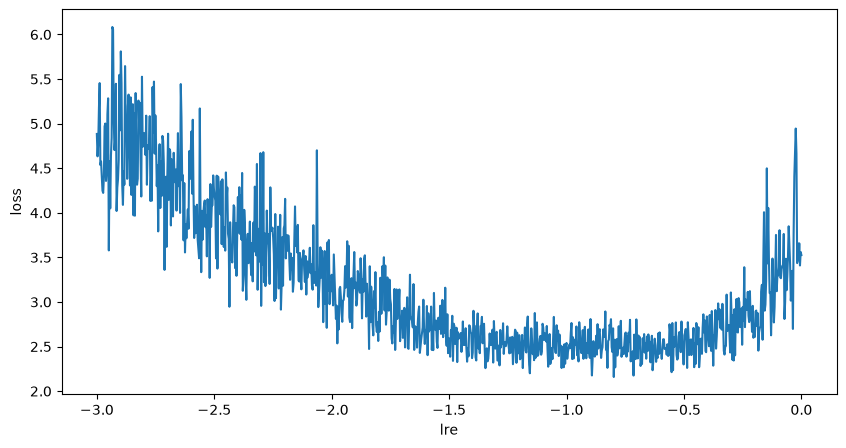

In [197]:
# Plot loss vs. learning rate exponent
plt.figure(figsize=(10, 5))
plt.plot(lre, lossi)
plt.xlabel('Learning Rate Exponent (log10(lr))')
plt.ylabel('Loss')

## 4. Scaled Model Training & Evaluation
With the optimal learning rate established (~0.1), we scale up the model:
- Increase context window to `block_size = 4`
- Increase capacity: `emb_dim = 10`, `hidden_size = 300`
- Apply proper weight initialization (Kaiming / LeCun init) to fix initial loss explosion
- Split dataset: 80% Train, 10% Dev (Validation), 10% Test
- Train with mini-batches and step decay (0.1 for 50k steps, then 0.01 for 25k steps)

### 4.1 Dataset Builder & Train / Dev / Test Splits

In [279]:
# Dataset builder supporting configurable context size
block_size = 4

def build_dataset(words):
    X, y = [], []

    for w in words:
        context = [0] * block_size
        
        for ch in w + '.':
            X.append(context)
            iy = stoi[ch]
            y.append(iy)
            context = context[1:] + [iy]
    
    X = torch.tensor(X)
    y = torch.tensor(y)
    
    return X, y

In [280]:
# Split dataset into train (80%), dev/validation (10%), test (10%)
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, ytr = build_dataset(words[:n1])
Xdev, ydev = build_dataset(words[n1:n2])
Xte, yte = build_dataset(words[n2:])

### 4.2 Scaled Architecture & Proper Weight Initialization
Weights are scaled inversely with the square root of fan-in (LeCun / Kaiming init) and biases initialized to zero.

In [283]:
emb_dim = 10
vocab_size = 27
hidden_size = 300

# Proper weight initialization to avoid saturated tanh neurons and exploding initial loss
C = torch.randn(vocab_size, emb_dim) * 0.1
W1 = torch.randn(hidden_size, block_size * emb_dim) * ((block_size * emb_dim) ** -0.5) # LeCun/Xavier Initialization
b1 = torch.zeros(hidden_size)
W2 = torch.randn(vocab_size, hidden_size) * (hidden_size ** -0.5)
b2 = torch.zeros(vocab_size)

params = [C, W1, W2, b1, b2]

for p in params:
    p.requires_grad = True

print(sum(p.numel() for p in params))

20697


### 4.3 Training Loop with Learning Rate Decay
We train for 75,000 steps using mini-batch gradient descent (batch size 256), decaying the learning rate from 0.1 to 0.01 at step 50,000.

In [284]:
steps = 75000
batch_size = 256
N = len(Xtr)
running_loss = None

for i in range(steps):
    # Sample mini-batch
    ix = torch.randint(0, N, (batch_size,))
    X_b = Xtr[ix]
    y_b = ytr[ix]

    # Forward pass
    X_emb = C[X_b].reshape(-1, emb_dim * block_size)
    h = torch.tanh(X_emb @ W1.T + b1)
    logits = h @ W2.T + b2
    loss = F.cross_entropy(logits, y_b)
    current_loss = loss.item()

    # Track smoothed loss
    if running_loss is None:
        running_loss = current_loss
    else:
        running_loss = 0.95 * running_loss + 0.05 * current_loss

    # Zero gradients
    for p in params:
        p.grad = None

    # Backward pass
    loss.backward()

    # Learning rate schedule: step decay from 0.1 to 0.01 at step 50,000
    lr = 0.1 if i < 50000 else 0.01
    for p in params:
        p.data += -lr * p.grad

    if i % 1000 == 0:
        print(f"Step {i:5d} | Smoothed Loss: {running_loss:.4f} (Batch: {current_loss:.4f})")

Step     0 | Smoothed Loss: 3.2956 (Batch: 3.2956)
Step  1000 | Smoothed Loss: 2.3395 (Batch: 2.2950)
Step  2000 | Smoothed Loss: 2.3015 (Batch: 2.1723)
Step  3000 | Smoothed Loss: 2.2860 (Batch: 2.2157)
Step  4000 | Smoothed Loss: 2.2901 (Batch: 2.2989)
Step  5000 | Smoothed Loss: 2.2492 (Batch: 2.1883)
Step  6000 | Smoothed Loss: 2.2525 (Batch: 2.3105)
Step  7000 | Smoothed Loss: 2.2606 (Batch: 2.3534)
Step  8000 | Smoothed Loss: 2.2477 (Batch: 2.3719)
Step  9000 | Smoothed Loss: 2.1982 (Batch: 2.1795)
Step 10000 | Smoothed Loss: 2.1865 (Batch: 2.1080)
Step 11000 | Smoothed Loss: 2.1790 (Batch: 2.1699)
Step 12000 | Smoothed Loss: 2.1752 (Batch: 2.1797)
Step 13000 | Smoothed Loss: 2.1777 (Batch: 2.2653)
Step 14000 | Smoothed Loss: 2.1634 (Batch: 2.2377)
Step 15000 | Smoothed Loss: 2.1652 (Batch: 2.1977)
Step 16000 | Smoothed Loss: 2.1402 (Batch: 2.0449)
Step 17000 | Smoothed Loss: 2.1396 (Batch: 2.1339)
Step 18000 | Smoothed Loss: 2.1448 (Batch: 2.1707)
Step 19000 | Smoothed Loss: 2.0

### 4.4 Model Evaluation (Validation & Test Sets)

In [285]:
# Validation loss
X_dev_emb = C[Xdev].reshape(-1, emb_dim * block_size)
h = torch.tanh(X_dev_emb @ W1.T + b1)
logits = h @ W2.T + b2 
val_loss = F.cross_entropy(logits, ydev)
val_loss.item()

2.0341546535491943

In [286]:
# Test loss
X_emb = C[Xte].reshape(-1, emb_dim * block_size)
h = torch.tanh(X_emb @ W1.T + b1)
logits = h @ W2.T + b2 
test_loss = F.cross_entropy(logits, yte)
test_loss.item()

2.0444116592407227

### 4.5 Sampling New Names
Generate new names character-by-character from the trained model by iteratively predicting the next token and shifting the context window.

In [294]:
block_size

4

In [296]:
# Sample 10 names from the trained model
for _ in range(10):
    out = []
    context = [0] * block_size
    
    while True:
        x_emb = C[context].reshape(-1, emb_dim*block_size)
        h = torch.tanh(x_emb @ W1.T + b1)
        logits = h @ W2.T + b2
        counts = logits.exp()
        probs = counts / counts.sum(1, keepdim=True)
        ix = torch.multinomial(probs, num_samples=1).item()
        if ix == 0:
            break
        out.append(itos[ix])

        context = context[1:] + [ix]
    print(''.join(out))

tysh
zaharroycessin
sedgie
calayuar
adylan
kadif
sanvithai
uraiin
kahlyn
iriyah
